# K-Nearest Neighbors (KNN) from Scratch

## 1. Overview and Intuition
**K-Nearest Neighbors (KNN)** is a non-parametric, instance-based (*lazy learning*) supervised algorithm. Unlike model-based algorithms that estimate explicit parameters during a dedicated training phase, KNN defers computation until inference time: it simply stores the training dataset and queries it directly.

### Mathematical Formulation
Given a labeled training set $\mathcal{D} = \{(x_1, y_1), (x_2, y_2), \dots, (x_N, y_N)\}$ where $x_i \in \mathbb{R}^D$ and $y_i \in \mathcal{C}$, and an unseen query vector $x^* \in \mathbb{R}^D$:

1. **Distance Metric (Euclidean L2):**
   $$d(x^*, x_i) = \|x^* - x_i\|_2 = \sqrt{\sum_{j=1}^D (x^*_j - x_{i,j})^2}$$
2. **Neighborhood Selection:**
   Find the subset $\mathcal{N}_K(x^*) \subset \mathcal{D}$ containing the $K$ training samples with the smallest distances to $x^*$.
3. **Majority Voting (Classification):**
   The predicted class $\hat{y}$ is chosen by plurality vote among the $K$ nearest neighbors:
   $$\hat{y} = \arg\max_{c \in \mathcal{C}} \sum_{i \in \mathcal{N}_K(x^*)} \mathbb{I}(y_i = c)$$

### Computational Complexity
- **Naive Sorting:** Computes all $N$ pairwise distances and sorts the full array:  
  *Time:* $\mathcal{O}(N \cdot D + N \log N)$ | *Space:* $\mathcal{O}(N)$
- **Heap-Optimized (Bounded Max-Heap):** Tracks only the $K$ smallest distances using a max-heap of size $K$:  
  *Time:* $\mathcal{O}(N \cdot D + N \log K)$ | *Space:* $\mathcal{O}(K)$

## 2. Implementation in Pure Python (Zero Dependencies)

In [1]:
import heapq
import math
from collections import Counter
from typing import Any, Callable, Generator, List, Sequence, Tuple


def euclidean_distance(a: Sequence[float], b: Sequence[float]) -> float:
    """Calculates the Euclidean (L2) distance between two points."""
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))


def knn_predict_naive(
    X_train: List[List[float]],
    y_train: List[Any],
    x_query: List[float],
    k: int,
    distance_fn: Callable[[Sequence[float], Sequence[float]], float] = euclidean_distance,
) -> Any:
    """Predicts the class label for a query point using full distance sorting. O(N log N)."""
    distances = [
        (distance_fn(x, x_query), label)
        for x, label in zip(X_train, y_train)
    ]
    distances.sort(key=lambda item: item[0])
    k_nearest_labels = [label for _, label in distances[:k]]
    most_common = Counter(k_nearest_labels).most_common(1)
    return most_common[0][0]


def knn_predict_heap(
    X_train: List[List[float]],
    y_train: List[Any],
    x_query: List[float],
    k: int,
    distance_fn: Callable[[Sequence[float], Sequence[float]], float] = euclidean_distance,
) -> Any:
    """Predicts class label using heapq.nsmallest with a generator. O(N log K) time, O(K) memory."""
    # Generator expression avoids allocating an O(N) intermediate list in memory
    distance_stream: Generator[Tuple[float, Any], None, None] = (
        (distance_fn(x, x_query), label)
        for x, label in zip(X_train, y_train)
    )
    k_nearest = heapq.nsmallest(k, distance_stream, key=lambda item: item[0])
    k_labels = [label for _, label in k_nearest]
    return Counter(k_labels).most_common(1)[0][0]


def knn_predict_batch(
    X_train: List[List[float]],
    y_train: List[Any],
    X_test: List[List[float]],
    k: int,
) -> List[Any]:
    """Predicts labels for multiple test queries."""
    return [knn_predict_heap(X_train, y_train, x, k) for x in X_test]

## 3. Demonstration & Accuracy on Synthetic 2D Dataset

In [2]:
import random
random.seed(42)

# Create 3 classes in 2D feature space
class_A = [[random.gauss(2.0, 0.8), random.gauss(2.0, 0.8)] for _ in range(30)]
class_B = [[random.gauss(6.0, 0.8), random.gauss(6.0, 0.8)] for _ in range(30)]
class_C = [[random.gauss(2.0, 0.8), random.gauss(7.0, 0.8)] for _ in range(30)]

X_train = class_A + class_B + class_C
y_train = ["Class A"] * 30 + ["Class B"] * 30 + ["Class C"] * 30

# Test query points
X_test = [
    [1.8, 2.2],   # Expected: Class A
    [5.9, 6.2],   # Expected: Class B
    [2.1, 6.8],   # Expected: Class C
    [4.0, 4.0],   # Boundary region
]

k = 5
predictions = knn_predict_batch(X_train, y_train, X_test, k=k)

for point, pred in zip(X_test, predictions):
    print(f"Query Point {point} -> Predicted: {pred}")

Query Point [1.8, 2.2] -> Predicted: Class A
Query Point [5.9, 6.2] -> Predicted: Class B
Query Point [2.1, 6.8] -> Predicted: Class C
Query Point [4.0, 4.0] -> Predicted: Class B


## 4. Visualizing Decision Boundaries with Matplotlib

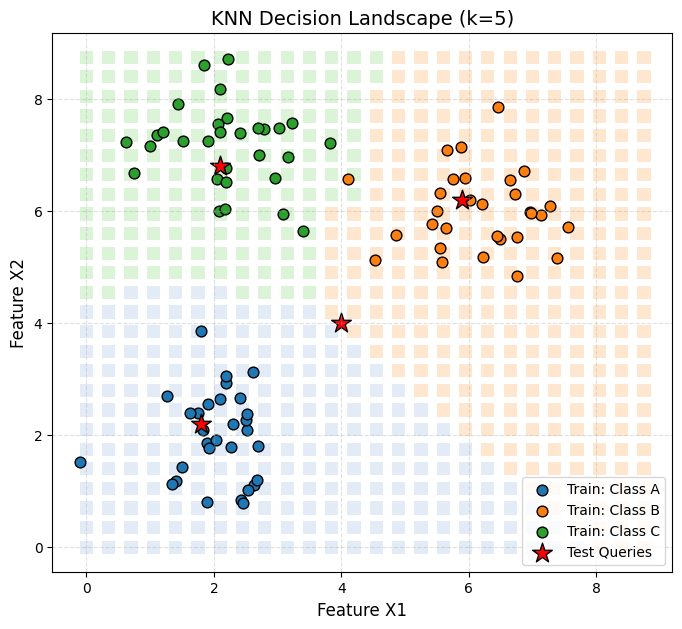

In [3]:
try:
    import matplotlib.pyplot as plt

    # Generate 2D grid covering feature space
    x_min, x_max = 0.0, 9.0
    y_min, y_max = 0.0, 9.0
    step = 0.35

    grid_pts = []
    x_coords = []
    y_coords = []
    curr_x = x_min
    while curr_x <= x_max:
        curr_y = y_min
        while curr_y <= y_max:
            grid_pts.append([curr_x, curr_y])
            x_coords.append(curr_x)
            y_coords.append(curr_y)
            curr_y += step
        curr_x += step

    grid_preds = knn_predict_batch(X_train, y_train, grid_pts, k=5)
    label_to_color = {"Class A": "#aec7e8", "Class B": "#ffbb78", "Class C": "#98df8a"}
    point_to_color = {"Class A": "#1f77b4", "Class B": "#ff7f0e", "Class C": "#2ca02c"}

    fig, ax = plt.subplots(figsize=(8, 7))

    # Plot background decision landscape
    grid_colors = [label_to_color[p] for p in grid_preds]
    ax.scatter(x_coords, y_coords, c=grid_colors, marker="s", s=90, alpha=0.35, edgecolors="none")

    # Plot training points
    for label in ["Class A", "Class B", "Class C"]:
        pts = [X_train[i] for i, y in enumerate(y_train) if y == label]
        ax.scatter([p[0] for p in pts], [p[1] for p in pts], c=point_to_color[label], label=f"Train: {label}", edgecolors="black", s=60)

    # Plot test queries
    ax.scatter([p[0] for p in X_test], [p[1] for p in X_test], c="red", marker="*", s=220, label="Test Queries", edgecolors="black")

    ax.set_title("KNN Decision Landscape (k=5)", fontsize=14)
    ax.set_xlabel("Feature X1", fontsize=12)
    ax.set_ylabel("Feature X2", fontsize=12)
    ax.legend(loc="lower right")
    ax.grid(True, linestyle="--", alpha=0.4)
    plt.show()
except ImportError:
    print("matplotlib is not installed in the environment. Skipping visual plot.")